In [2]:
from StochasticCliffWalking import StochasticCliffWalkingEnv
from episode_generator import generate_episode
from tqdm import tqdm

import matplotlib.pyplot as plt
import numpy as np

In [3]:
env = StochasticCliffWalkingEnv()

In [4]:
def iterative_policy_evaluation(env, gamma = 0.99, threshold = 1e-6):
    V = np.zeros(env.nS)

    policy = 1.0 / env.nA

    while True:
        V_diff = 0
        for state in range(env.nS):
            v_s = 0
            for action in range(env.nA):
                q_s = 0
                for prob, next_state, reward, done in env.P[state][action]:
                    q_s += prob * (reward + gamma * V[next_state])
                v_s += (policy * q_s)
        
            V_diff = max(V_diff, abs(v_s - V[state]))
            V[state] = v_s
        
        if V_diff < threshold:
            break
    
    return V

V_true = iterative_policy_evaluation(env)

In [11]:
V_true

array([ -929.126926  ,  -933.74545207,  -937.73881488,  -938.88919393,
        -936.27654442,  -928.91111421,  -915.05863301,  -891.87806816,
        -855.42005255,  -801.86129352,  -732.61704614,  -668.42064202,
        -958.0084817 ,  -968.05730318,  -974.42983447,  -976.54673824,
        -974.81827927,  -968.88952615,  -957.31838135,  -937.15059504,
        -903.04282082,  -845.9048163 ,  -753.12948971,  -627.19073047,
       -1011.50822823, -1041.11846878, -1050.70698186, -1053.46567703,
       -1052.90650328, -1049.61697917, -1042.81389956, -1030.18737811,
       -1006.14199569,  -955.72323107,  -833.19443761,  -481.32269633,
       -1072.22635244, -1104.30488771, -1131.4280447 , -1132.11082175,
       -1131.97242625, -1131.15826903, -1129.47450683, -1126.34944277,
       -1120.39821062, -1107.91956638,  -787.21766777,     0.        ])

In [5]:
def every_visit_monte_carlo_prediction(env, episodes = 50000, gamma = 0.99):
    V = np.zeros(env.nS)
    state_counts = np.zeros(env.nS)

    target_states = [36, 29, 5]
    V_history = {s: [] for s in target_states}
    rmse_history = []

    # This code is for using same structure for create episode
    policy = lambda s: np.ones(env.nA) / env.nA

    for _ in tqdm(range(episodes)):
        states, _, rewards = generate_episode(policy, env)

        G = 0
        for t in reversed(range(len(states))):
            state = states[t]
            reward = rewards[t]

            G = gamma * G + reward

            state_counts[state] += 1
            V[state] += (G - V[state]) / state_counts[state]
        
        for s in target_states:
            V_history[s].append(V[s])
        
        rmse = np.sqrt(np.mean((V - V_true) ** 2))
        rmse_history.append(rmse)
    
    return V, V_history, rmse_history

V_mc, V_history_mc, rmse_history_mc = every_visit_monte_carlo_prediction(env)

  0%|          | 0/50000 [00:00<?, ?it/s]

100%|██████████| 50000/50000 [07:06<00:00, 117.26it/s]


In [13]:
def td0_prediction(env, episodes = 50000, gamma = 0.99, alpha = 0.01):
    V = np.zeros(env.nS)

    target_states = [36, 29, 5]
    V_history = {s: [] for s in target_states}
    rmse_history = []

    policy = lambda s: np.ones(env.nA) / env.nA

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()
        episode_finish = False

        while not episode_finish:
            action_probs = policy(state)
            selected_action = np.random.choice(len(action_probs), p=action_probs)

            next_state, reward, terminated, truncated, _ = env.step(selected_action)

            episode_finish = terminated or truncated
        
            if episode_finish:
                update_step = reward
            else:
                update_step = reward + gamma * V[next_state]
            
            V[state] += alpha * (update_step - V[state])
            state = next_state
        
        for s in target_states:
            V_history[s].append(V[s])
        
        rmse = np.sqrt(np.mean((V - V_true) ** 2))
        rmse_history.append(rmse)
    
    return V, V_history, rmse_history

V_td0, V_history_td0, rmse_history_td0 = td0_prediction(env)

100%|██████████| 50000/50000 [05:23<00:00, 154.77it/s]


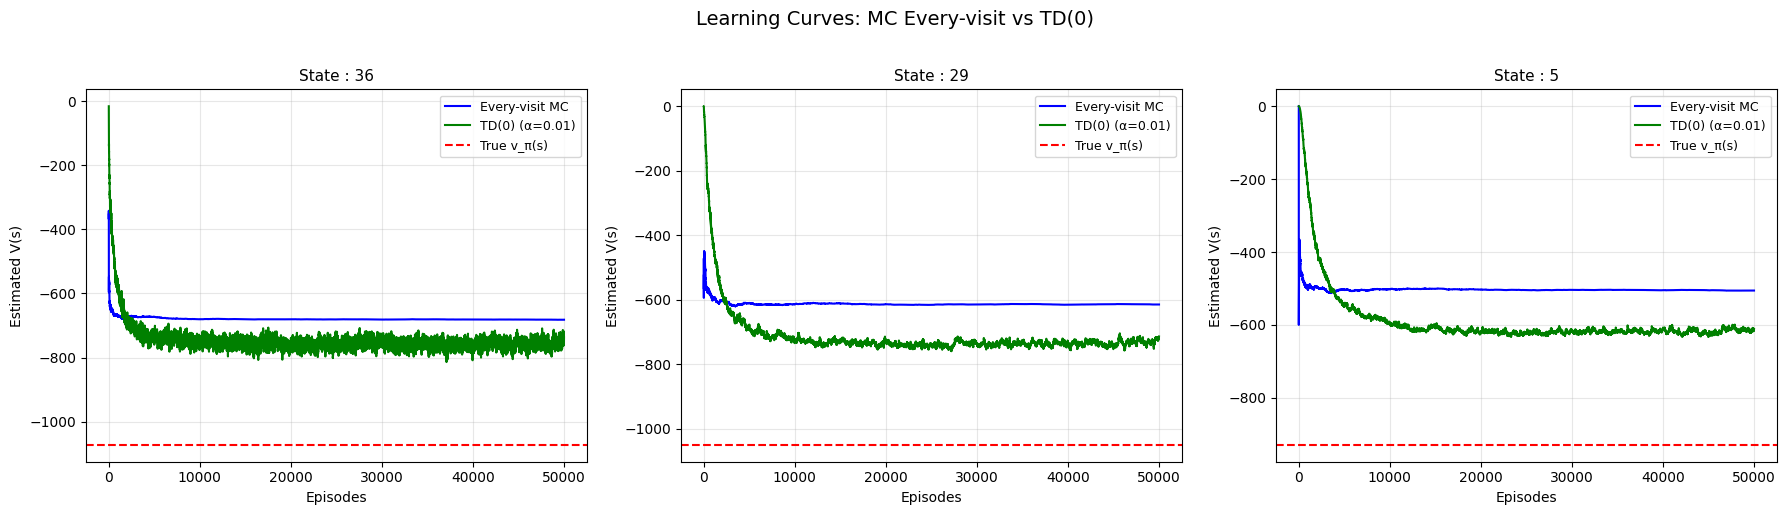

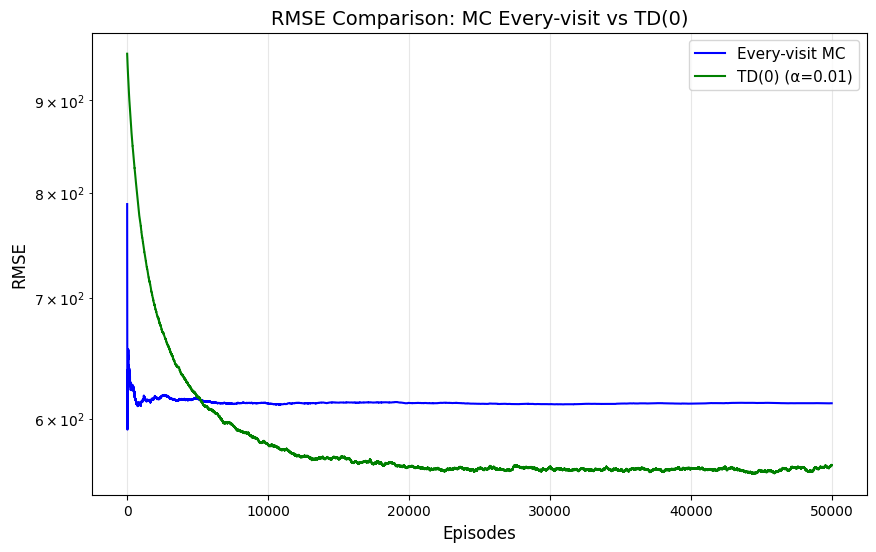

In [14]:
def plot_mc_td_vals(V_true, V_history_mc, V_history_td0):
    epsode_len = len(V_history_td0[36])
    episodes = np.arange(1, epsode_len + 1)

    _, axes = plt.subplots(1, 3, figsize=(18, 5))

    for idx, (state, ـ) in enumerate(V_history_td0.items()):
        true_vals = V_true[state]
        mc_vals = V_history_mc[state]
        td_vals = V_history_td0[state]

        axes[idx].plot(episodes, mc_vals, 'b-', label='Every-visit MC', linewidth=1.5)
        axes[idx].plot(episodes, td_vals, 'g-', label='TD(0) (α=0.01)', linewidth=1.5)
        axes[idx].axhline(y=true_vals, color='r', linestyle='--', label='True v_π(s)', linewidth=1.5)
        axes[idx].set_xlabel('Episodes', fontsize=10)
        axes[idx].set_ylabel('Estimated V(s)', fontsize=10)
        axes[idx].set_title(f"State : {state}", fontsize=11)
        axes[idx].legend(fontsize=9)
        axes[idx].grid(True, alpha=0.3)

    plt.suptitle('Learning Curves: MC Every-visit vs TD(0)', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig("homework-2-1.png")
    plt.show()

def plot_rmse(rmse_history_mc, rmse_history_td0):
    episodes = np.arange(1, len(rmse_history_mc) + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(episodes, rmse_history_mc, 'b-', label='Every-visit MC', linewidth=1.5)
    plt.plot(episodes, rmse_history_td0, 'g-', label='TD(0) (α=0.01)', linewidth=1.5)
    plt.xlabel('Episodes', fontsize=12)
    plt.ylabel('RMSE', fontsize=12)
    plt.title('RMSE Comparison: MC Every-visit vs TD(0)', fontsize=14)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.yscale('log')
    plt.savefig("homework-2-2.png")
    plt.show()

plot_mc_td_vals(V_true, V_history_mc, V_history_td0)
plot_rmse(rmse_history_mc, rmse_history_td0)

In [15]:
def n_step_td_prediction(env, n, episodes = 50000, gamma = 0.99, alpha = 0.01):
    V = np.zeros(env.nS)

    target_states = [36, 29, 5]
    V_history = {s: [] for s in target_states}
    rmse_history = []

    # This code is for using same structure for create episode
    policy = lambda s: np.ones(env.nA) / env.nA

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()
        rewards = []
        states = [state]

        T = float('inf')
        t = 0

        while True:
            if t < T:
                action_probs = policy(state)
                selected_action = np.random.choice(len(action_probs), p=action_probs)
                next_state, reward, terminated, truncated, _ = env.step(selected_action)

                rewards.append(reward)
                states.append(next_state)

                if terminated or truncated:
                    T = t + 1
                else:
                    state = next_state

            tou = t - n + 1

            if tou >= 0:
                G = 0
                for i in range(tou + 1,int(min(tou + n, T))):
                    G += (gamma ** (i - tou - 1)) * rewards[i-1]

                if tou + n < T:
                    G += (gamma ** n) * V[states[tou + n]]

                V[states[tou]] += alpha * (G - V[states[tou]])
            
            if tou == T - 1:
                break
            
            t += 1
        
        for s in target_states:
            V_history[s].append(V[s])
        
        if V_true is not None:
            rmse = np.sqrt(np.mean((V - V_true) ** 2))
            rmse_history.append(rmse)
    
    return V, V_history, rmse_history

all_n = [1, 2, 4, 8, 100]
V_prediction_histories = {}
rmse_prediction_histories = {}

for n in all_n:
    V_tdn, V_history_tdn, rmse_history_tdn = n_step_td_prediction(env, n)
    V_prediction_histories[n] = V_history_tdn
    rmse_prediction_histories[n] = rmse_history_tdn

100%|██████████| 50000/50000 [06:35<00:00, 126.33it/s]


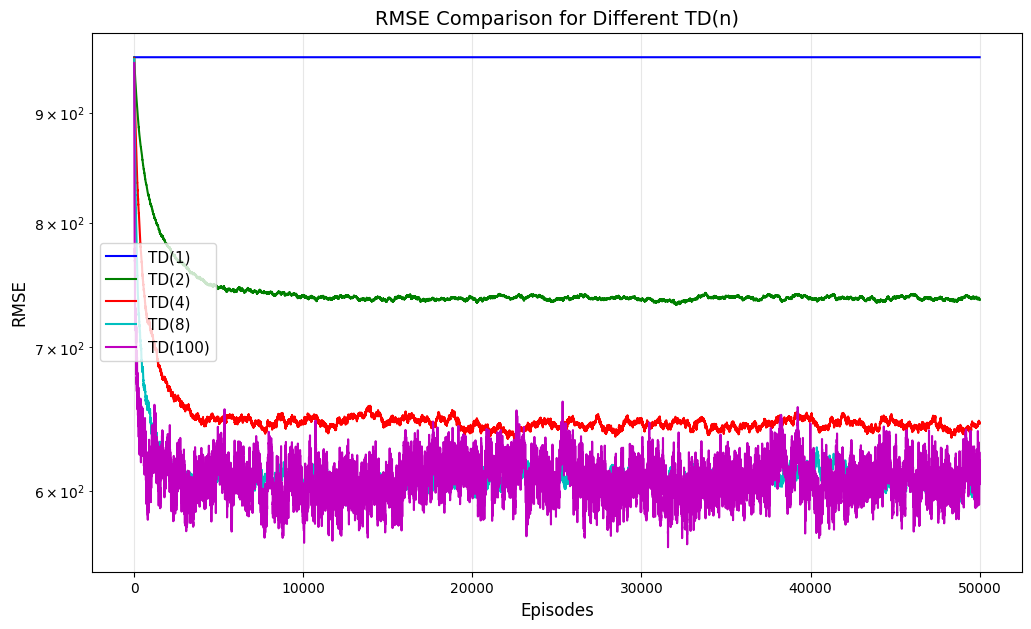

In [16]:
def plot_tdn_vals(V_true, V_history_tdn):
    all_n = list(V_history_tdn.keys())
    
    first_n = all_n[0]
    states = list(V_history_tdn[first_n].keys())
    
    episodes_len = len(V_history_tdn[first_n][states[0]])
    episodes = np.arange(1, episodes_len + 1)
    
    for state in states:
        plt.figure(figsize=(10, 6))
        
        for n in all_n:
            td_vals = V_history_tdn[n][state]
            plt.plot(episodes, td_vals, linewidth=1.5, label=f'TD({n})')

        true_val = V_true[state]
        plt.axhline(y=true_val, color='r', linestyle='--', 
                    label='True v_π(s)', linewidth=1.5)
        
        plt.xlabel('Episodes', fontsize=12)
        plt.ylabel('Estimated V(s)', fontsize=12)
        plt.title(f'Learning Curves: TD(n) for State {state}', fontsize=14)
        plt.legend(fontsize=10)
        plt.grid(True, alpha=0.3)
        plt.show()


def plot_rmse(rmse_history_tdn):
    all_n = list(rmse_history_tdn.keys())
    
    first_n = all_n[0]
    episodes_len = len(rmse_history_tdn[first_n])
    episodes = np.arange(1, episodes_len + 1)
    
    plt.figure(figsize=(12, 7))
    
    colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange', 'purple', 'brown']
    
    for i, n in enumerate(all_n):
        rmse_vals = rmse_history_tdn[n]
        color = colors[i % len(colors)]
        plt.plot(episodes, rmse_vals, color=color, linewidth=1.5, label=f'TD({n})')
    
    plt.xlabel('Episodes', fontsize=12)
    plt.ylabel('RMSE', fontsize=12)
    plt.title('RMSE Comparison for Different TD(n)', fontsize=14)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.yscale('log')
    plt.savefig("homework-2-3.png")
    plt.show()

# plot_tdn_vals(V_true, V_prediction_histories)
plot_rmse(rmse_prediction_histories)

In [7]:
def n_step_td_prediction_with_adaptive_alpha(env, n, episodes = 50000, gamma = 0.99):
    V = np.zeros(env.nS)

    N = np.zeros(env.nS)

    target_states = [36, 29, 5]
    V_history = {s: [] for s in target_states}
    rmse_history = []

    # This code is for using same structure for create episode
    policy = lambda s: np.ones(env.nA) / env.nA

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()
        rewards = []
        states = [state]

        T = float('inf')
        t = 0

        while True:
            if t < T:
                action_probs = policy(state)
                selected_action = np.random.choice(len(action_probs), p=action_probs)
                next_state, reward, terminated, truncated, _ = env.step(selected_action)

                rewards.append(reward)
                states.append(next_state)

                if terminated or truncated:
                    T = t + 1
                else:
                    state = next_state

            tou = t - n + 1

            if tou >= 0:
                G = 0
                for i in range(tou + 1,int(min(tou + n, T))):
                    G += (gamma ** (i - tou - 1)) * rewards[i-1]

                if tou + n < T:
                    G += (gamma ** n) * V[states[tou + n]]

                N[states[tou]] += 1

                adaptive_alpha = 1.0 / N[states[tou]]

                V[states[tou]] += adaptive_alpha * (G - V[states[tou]])
            
            if tou == T - 1:
                break
            
            t += 1
        
        for s in target_states:
            V_history[s].append(V[s])
        
        if V_true is not None:
            rmse = np.sqrt(np.mean((V - V_true) ** 2))
            rmse_history.append(rmse)
    
    return V, V_history, rmse_history

V_tdn, V_history_tdn, rmse_history_tdn = n_step_td_prediction_with_adaptive_alpha(env, 100)

100%|██████████| 50000/50000 [08:53<00:00, 93.64it/s] 


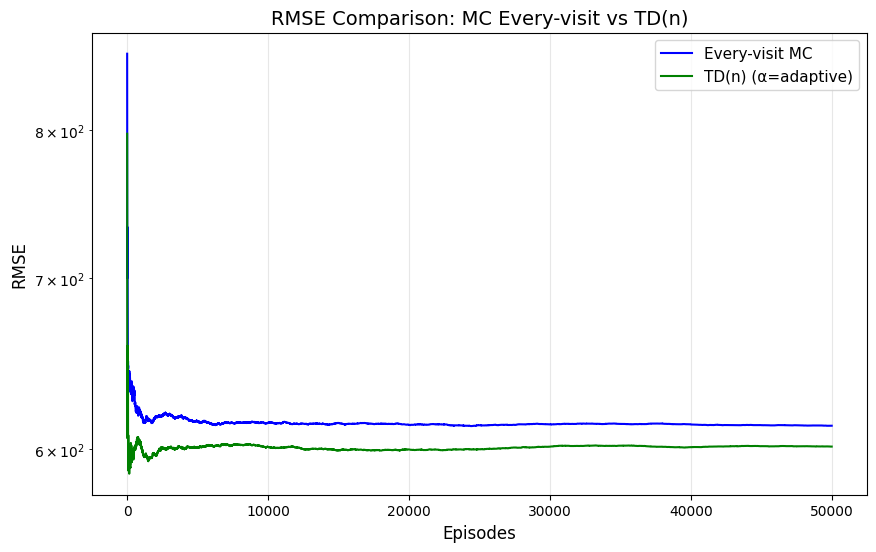

In [8]:
def plot_rmse_tdn_mc(rmse_history_mc, rmse_history_tdn):
    episodes = np.arange(1, len(rmse_history_mc) + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(episodes, rmse_history_mc, 'b-', label='Every-visit MC', linewidth=1.5)
    plt.plot(episodes, rmse_history_tdn, 'g-', label='TD(n) (α=adaptive)', linewidth=1.5)
    plt.xlabel('Episodes', fontsize=12)
    plt.ylabel('RMSE', fontsize=12)
    plt.title('RMSE Comparison: MC Every-visit vs TD(n)', fontsize=14)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.yscale('log')
    plt.savefig("homework-2-4.png")
    plt.show()


plot_rmse_tdn_mc(rmse_history_mc, rmse_history_tdn)